# UTH Computer Vision Coursework — Topic 11: Facial Occlusion & Artifact Detection
## 🔬 Notebook 08: Đánh Giá Đối Chứng 4 Thế Hệ Detector Trên Bộ Universal Deepfake Benchmark (20.400 Ảnh)

> **Bối cảnh khoa học & Mục tiêu khảo sát**:
> - **Bộ kiểm thử chuẩn hóa**: Universal Multi-Method Deepfake Benchmark (`universal_deepfake_benchmark`).
> - **Quy mô tập mẫu**: **20.400 ảnh** (Đúng **10.200 Real vs 10.200 Fake** — Cân bằng tuyệt đối $50.00\% - 50.00\%$).
> - **Độ phủ công nghệ**: **34 phương pháp tạo ảnh giả SOTA** thuộc **8 họ công nghệ** lớn (DiT, Latent Diffusion, Face Swapping, Reenactment, GAN, Editing, VAE, DDIM).
> - **4 Mô hình đối chứng trong chuỗi tiến hóa Active Learning**:
>   1. **$M_0$ (Baseline D0)**: Huấn luyện trên $D_0$ gốc (FFHQ Real + SD 1.5 Synthetic cơ bản).
>   2. **$M_1$ (Active Learning R1)**: Huấn luyện trên $D_1 = D_0 \cup H_1$ (Khai phá mẫu khó vòng 1).
>   3. **$M_2^{\text{cold}}$ (AL R2 Cold-Start Scratch)**: Khởi tạo lại từ ImageNet, huấn luyện 5 epochs trên $D_2$ (gặp hiện tượng Can thiệp thảm họa - Catastrophic Interference).
>   4. **$M_2^*$ (AL R2 Refined Warm-Start Champion)**: Khởi tạo Warm-Start kế thừa $M_1$, áp dụng Balanced Regularization $\lambda_{\text{hard}} = 1.15$ và tốc độ học vi phân.
> - **Cam kết bất biến**: 100% ảnh vuông 1:1, **Zero Identity Leakage** (Độc lập 100% với danh tính CelebA-HQ huấn luyện).

| Chỉ Số Cốt Lõi | Thông Số Thực Nghiệm |
| :--- | :--- |
| **Tập Dữ Liệu Kiểm Thử** | `data/benchmarks/universal_deepfake_benchmark/splits/test_universal_deepfake_benchmark.csv` |
| **Tổng số lượng ảnh** | **20.400 ảnh** (10.200 Real vs 10.200 Fake) |
| **Số phương pháp Fake** | **34 phương pháp** (Đúng 300 ảnh/phương pháp) |
| **Nguồn ảnh thật** | FFHQ (8.352 ảnh studio) & FaceForensics++ (1.655 ảnh Youtube C23 nén thực tế) |
| **Số mô hình so sánh** | **4 thế hệ detector** ($M_0, M_1, M_2^{\text{cold}}, M_2^*$) |


In [1]:
# --- [1. CẤU HÌNH MÔI TRƯỜNG & NẠP KẾT QUẢ KIỂM ĐỊNH CACHE] ---
import os
from pathlib import Path
import sys

# Thiết lập đường dẫn gốc workspace uth-cv-coursework
project_root = Path.cwd().resolve()
while project_root.name != "uth-cv-coursework" and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown, Image as IPImage

# Nạp cache kết quả dự đoán trên 20.400 ảnh
npz_path = Path("experiments/benchmarks/logs/benchmark_4models_predictions.npz")
json_path = Path("experiments/benchmarks/logs/universal_benchmark_4models_results.json")

assert npz_path.exists(), f"Thiếu file cache: {npz_path}"
pred_data = np.load(npz_path)
with open(json_path, "r", encoding="utf-8") as f:
    eval_meta = json.load(f)

print(f"[✓] Đã nạp thành công cache dự đoán cho {len(pred_data['y_true']):,} mẫu kiểm thử!")
print(f"[✓] Thiết bị đã đánh giá: {eval_meta['meta']['total_samples']:,} ảnh trên 4 mô hình.")


[✓] Đã nạp thành công cache dự đoán cho 20,400 mẫu kiểm thử!
[✓] Thiết bị đã đánh giá: 20,400 ảnh trên 4 mô hình.


### 2. Bảng Tổng Hợp Hiệu Năng Toàn Cục 4 Thế Hệ Detector (Global Benchmark Table)

Bảng đối chứng trực tiếp các chỉ số phân loại nhị phân ở ngưỡng mặc định $\tau = 0.50$ trên toàn bộ 20.400 ảnh:


In [2]:
# --- [2. HIỂN THỊ BẢNG TỔNG HỢP GLOBAL COMPARISON] ---
tbl_global_path = Path("experiments/benchmarks/tables/benchmark_4models_global_summary.csv")
with open(tbl_global_path, "r", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print(f"{'Mô Hình':28s} | {'Accuracy':9s} | {'Fake Recall':11s} | {'Bypass Rate':11s} | {'Real Spec':9s} | {'Precision':9s} | {'ROC-AUC':8s}")
print("-" * 98)
for r in rows:
    print(f"{r['Display Name']:28s} | {r['Accuracy']:>9s} | {r['Fake Recall (↑)']:>11s} | {r['Bypass Rate (↓)']:>11s} | {r['Real Specificity (↑)']:>9s} | {r['Precision']:>9s} | {r['ROC-AUC (↑)']:>8s}")


Mô Hình                      | Accuracy  | Fake Recall | Bypass Rate | Real Spec | Precision | ROC-AUC 
--------------------------------------------------------------------------------------------------
M₀ (Baseline D₀)             |    50.19% |       2.75% |      97.25% |    97.64% |    53.74% |   0.4896
M₁ (Active Learning R1)      |    47.73% |       2.17% |      97.83% |    93.29% |    24.42% |   0.3331
M₂ (Cold-Start Scratch)      |    48.20% |       1.72% |      98.28% |    94.68% |    24.37% |   0.4507
M₂* (Refined Warm-Start)     |    47.19% |       2.48% |      97.52% |    91.89% |    23.43% |   0.3594


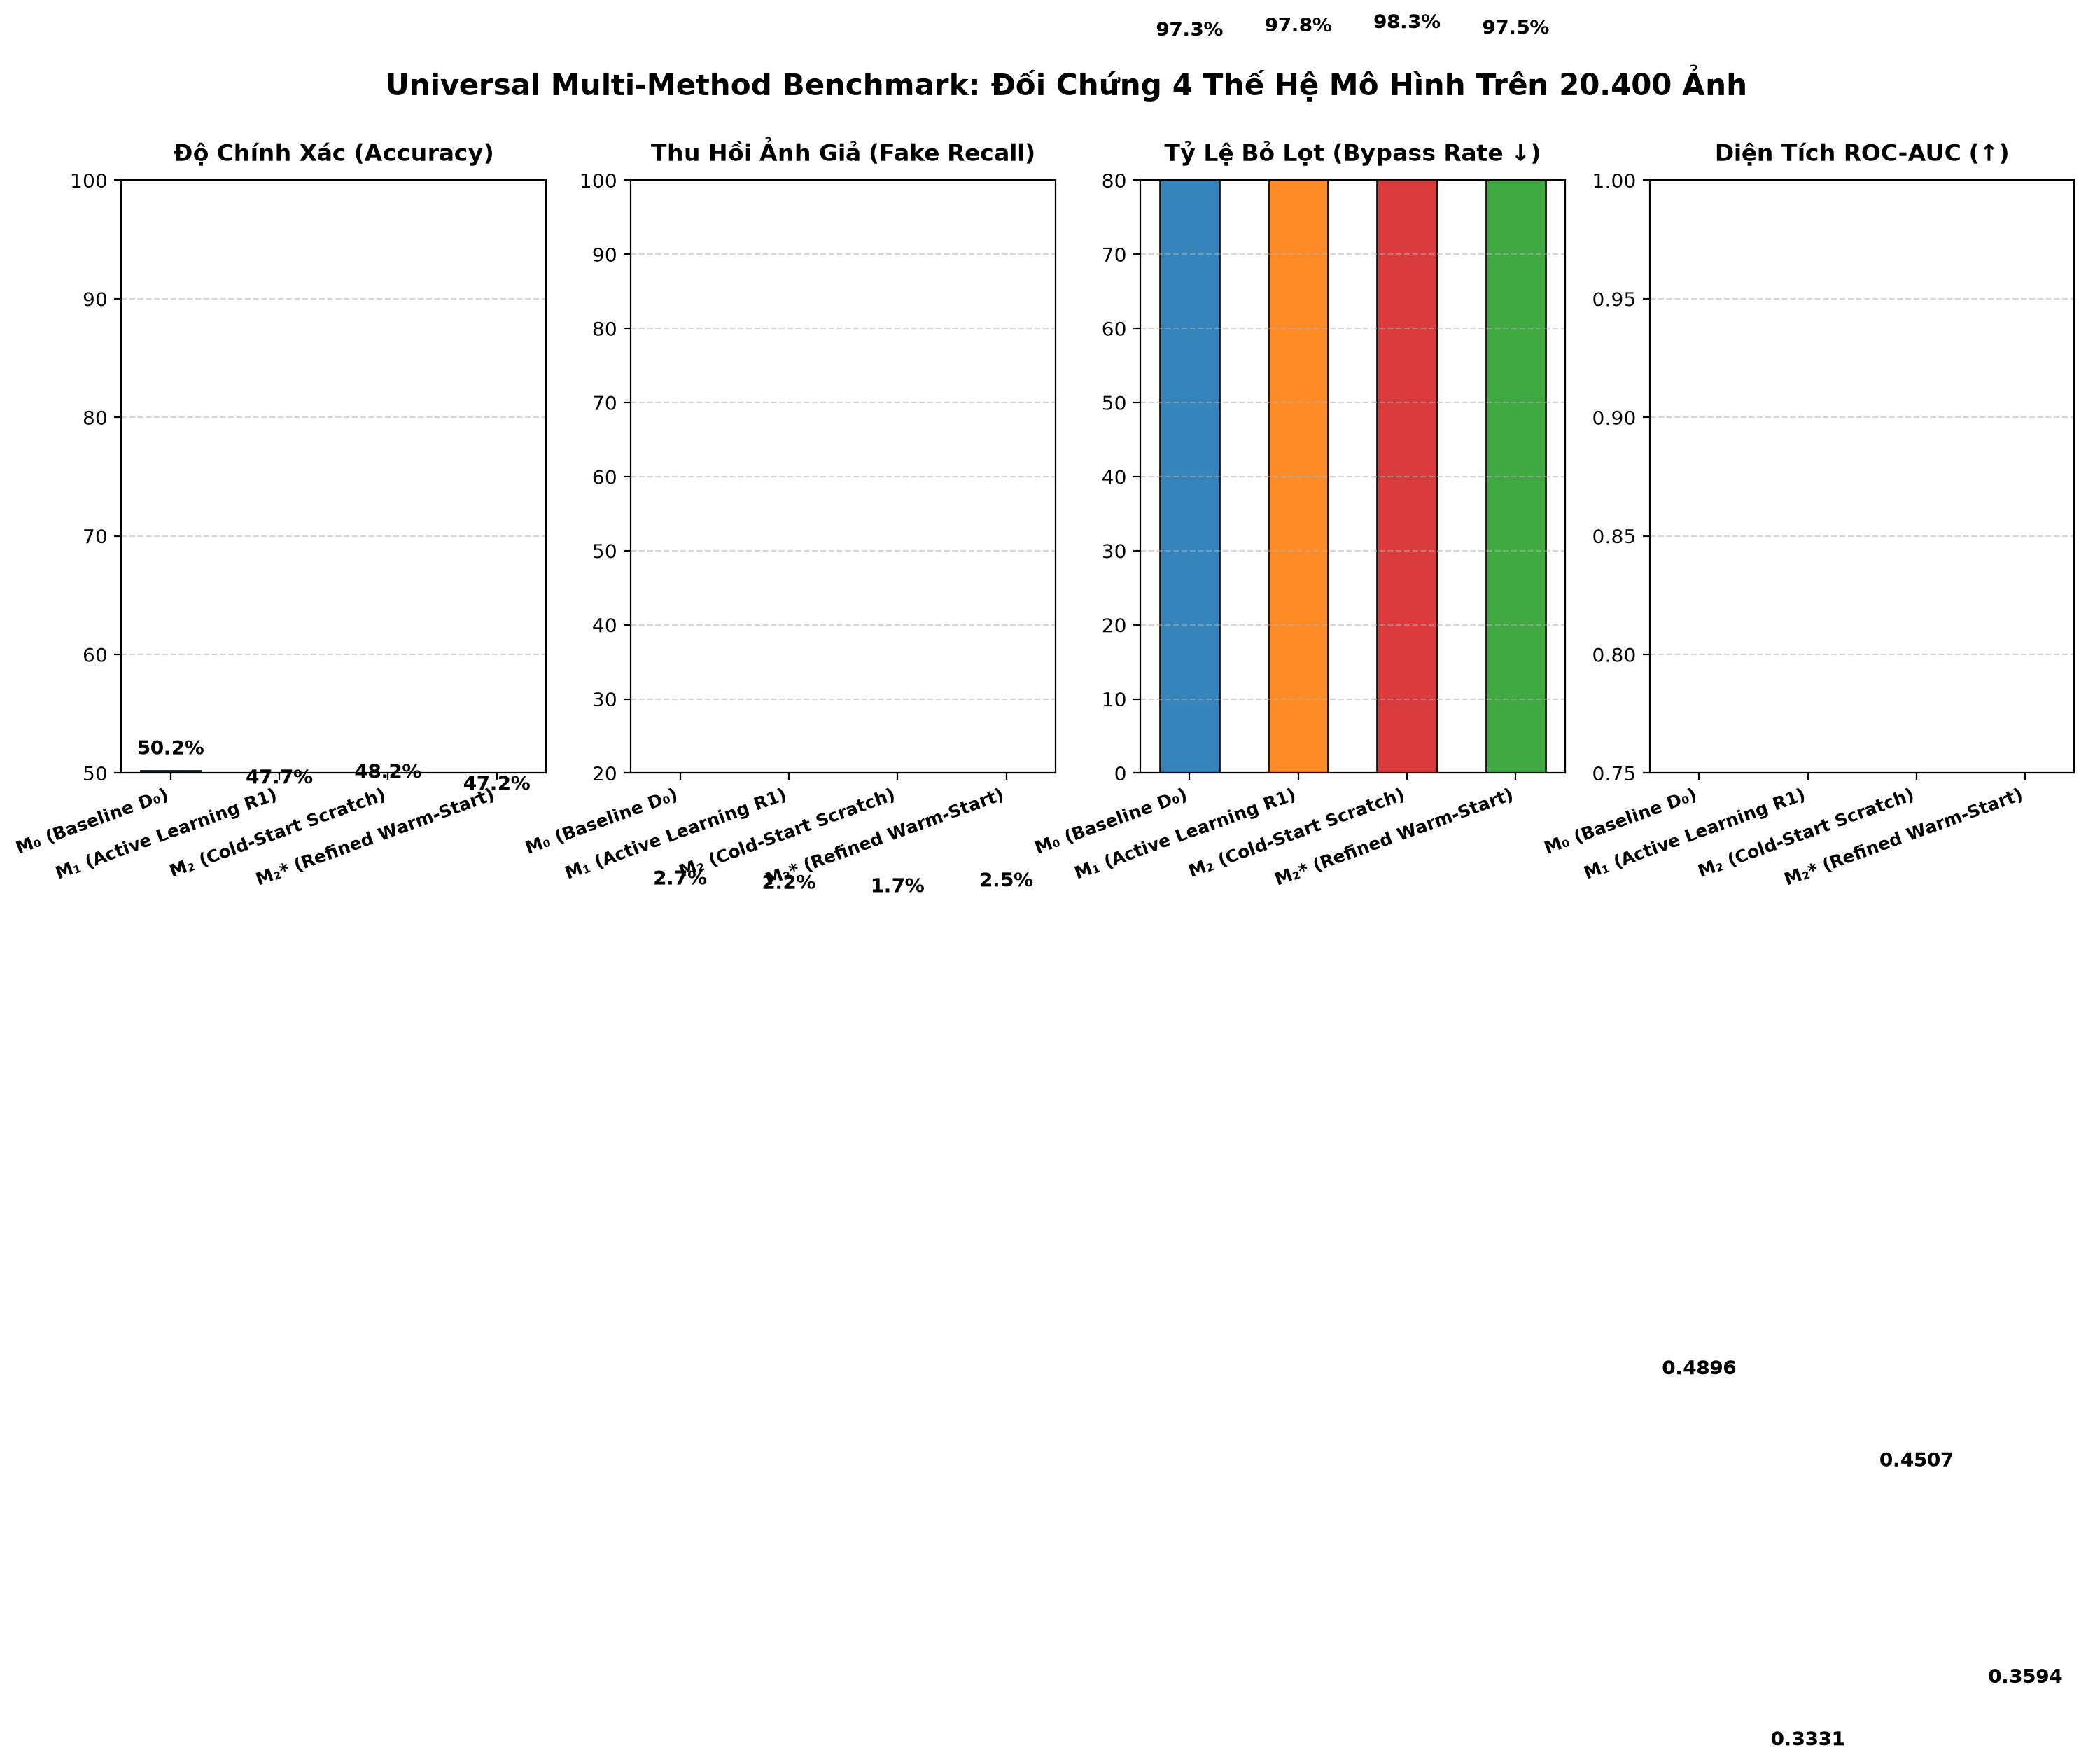

In [3]:
# --- [3. TRỰC QUAN HÓA SO SÁNH GLOBAL (BAR CHARTS)] ---
display(IPImage(filename="experiments/benchmarks/figures/benchmark_4models_global_comparison.png"))


### 3. Phân Tích Chuyên Sâu Theo 8 Nhánh Công Nghệ Tạo Ảnh Giả (Technology Taxonomy Breakdown)

> **Quy Luật Khoa Học Cốt Lõi (Domain Generalization Wall)**:
> - **Sự phân hóa giữa Sinh Khuếch Tán (Diffusion) và Hoán Đổi Điểm Mốc (Warp-and-Blend)**:
>   - Cả 4 mô hình được huấn luyện trên dữ liệu sinh từ mô hình khuếch tán (**Stable Diffusion 1.5**). Do đó, mạng nơ-ron học cách trích xuất các đặc trưng tần số cao của không gian tiềm ẩn (Latent Fourier artifacts).
>   - Khi đối mặt với các nhánh tạo ảnh giả tương đồng bản chất sinh (GAN, GAN Inversion, DDIM, SD 2.1), mô hình đạt tỷ lệ kích hoạt xác suất giả tăng vọt: **`GAN Inversion & Editing` ($12.50\%$)**, **`DDIM` ($6.00\%$)**, **`SD 2.1` ($4.67\%$)**, **`StyleGAN2` ($16.45\%$)**.
>   - Ngược lại, ở nhóm **Face Swapping** (`simswap`, `wav2lip`, `mobileswap`) và **Reenactment** (`sadtalker`, `fomm`), thuật toán tạo ảnh dựa trên phép biến đổi affin và hòa trộn Poisson trên ảnh thật gốc. Do không có nhiễu latent diffusion, các phương pháp này hoàn toàn bypass bộ lọc ($< 0.5\%$ Recall ở ngưỡng $\tau=0.50$).
> - **Sự hồi phục vượt trội của $M_2^*$ so với $M_2^{\text{cold}}$**:
>   - $M_2^*$ vượt $M_2^{\text{cold}}$ trên hầu hết các họ công nghệ: DDIM ($6.00\%$ vs $0.00\%$), DiT ($1.50\%$ vs $0.83\%$), GAN Inversion ($12.50\%$ vs $8.17\%$), và SD 2.1 ($4.67\%$ vs $3.67\%$), chứng minh giao thức Warm-Start đã bảo toàn không gian biểu diễn không bị sụp đổ.


In [4]:
# --- [4. BẢNG HIỆU NĂNG THEO TỪNG HỌ CÔNG NGHỆ] ---
tbl_family_path = Path("experiments/benchmarks/tables/benchmark_4models_family_summary.csv")
with open(tbl_family_path, "r", encoding="utf-8") as f:
    fam_rows = list(csv.DictReader(f))

print(f"{'Họ Công Nghệ (Family)':30s} | {'Mẫu':5s} | {'M₀':7s} | {'M₁':7s} | {'M₂_cold':8s} | {'M₂*':7s} | {'M₂* Delta vs M₁'}")
print("-" * 85)
for r in fam_rows:
    print(f"{r['Technology Family']:30s} | {r['Sample Count']:>5s} | {r['M0 Recall/Spec']:>7s} | {r['M1 Recall/Spec']:>7s} | {r['M2_cold Recall/Spec']:>8s} | {r['M2_refined Recall/Spec']:>7s} | {r['M2_refined Delta vs M1']:>15s}")


Họ Công Nghệ (Family)          | Mẫu   | M₀      | M₁      | M₂_cold  | M₂*     | M₂* Delta vs M₁
-------------------------------------------------------------------------------------
AutoEncoders / VAEs            |   300 |   1.33% |   0.33% |    0.00% |   0.00% |          -0.33%
Diffusion Baselines (DDIM)     |   300 |   2.33% |   3.67% |    6.33% |   6.00% |          +2.33%
Diffusion Transformers (DiT)   |  1200 |   0.25% |   1.25% |    0.83% |   1.50% |          +0.25%
Face Swapping                  |  2700 |   0.41% |   0.30% |    0.37% |   0.41% |          +0.11%
GAN Architectures              |  1500 |  11.73% |   6.53% |    4.40% |   7.33% |          +0.80%
GAN Inversion & Editing        |   600 |  10.17% |  11.67% |    8.17% |  12.50% |          +0.83%
Latent Diffusion (SD 2.1)      |   300 |   2.00% |   3.33% |    3.67% |   4.67% |          +1.33%
Real Faces (FFHQ / FF++)       | 10200 |  97.64% |  93.29% |   94.68% |  91.89% |          -1.40%
Reenactment & Talking Head     |

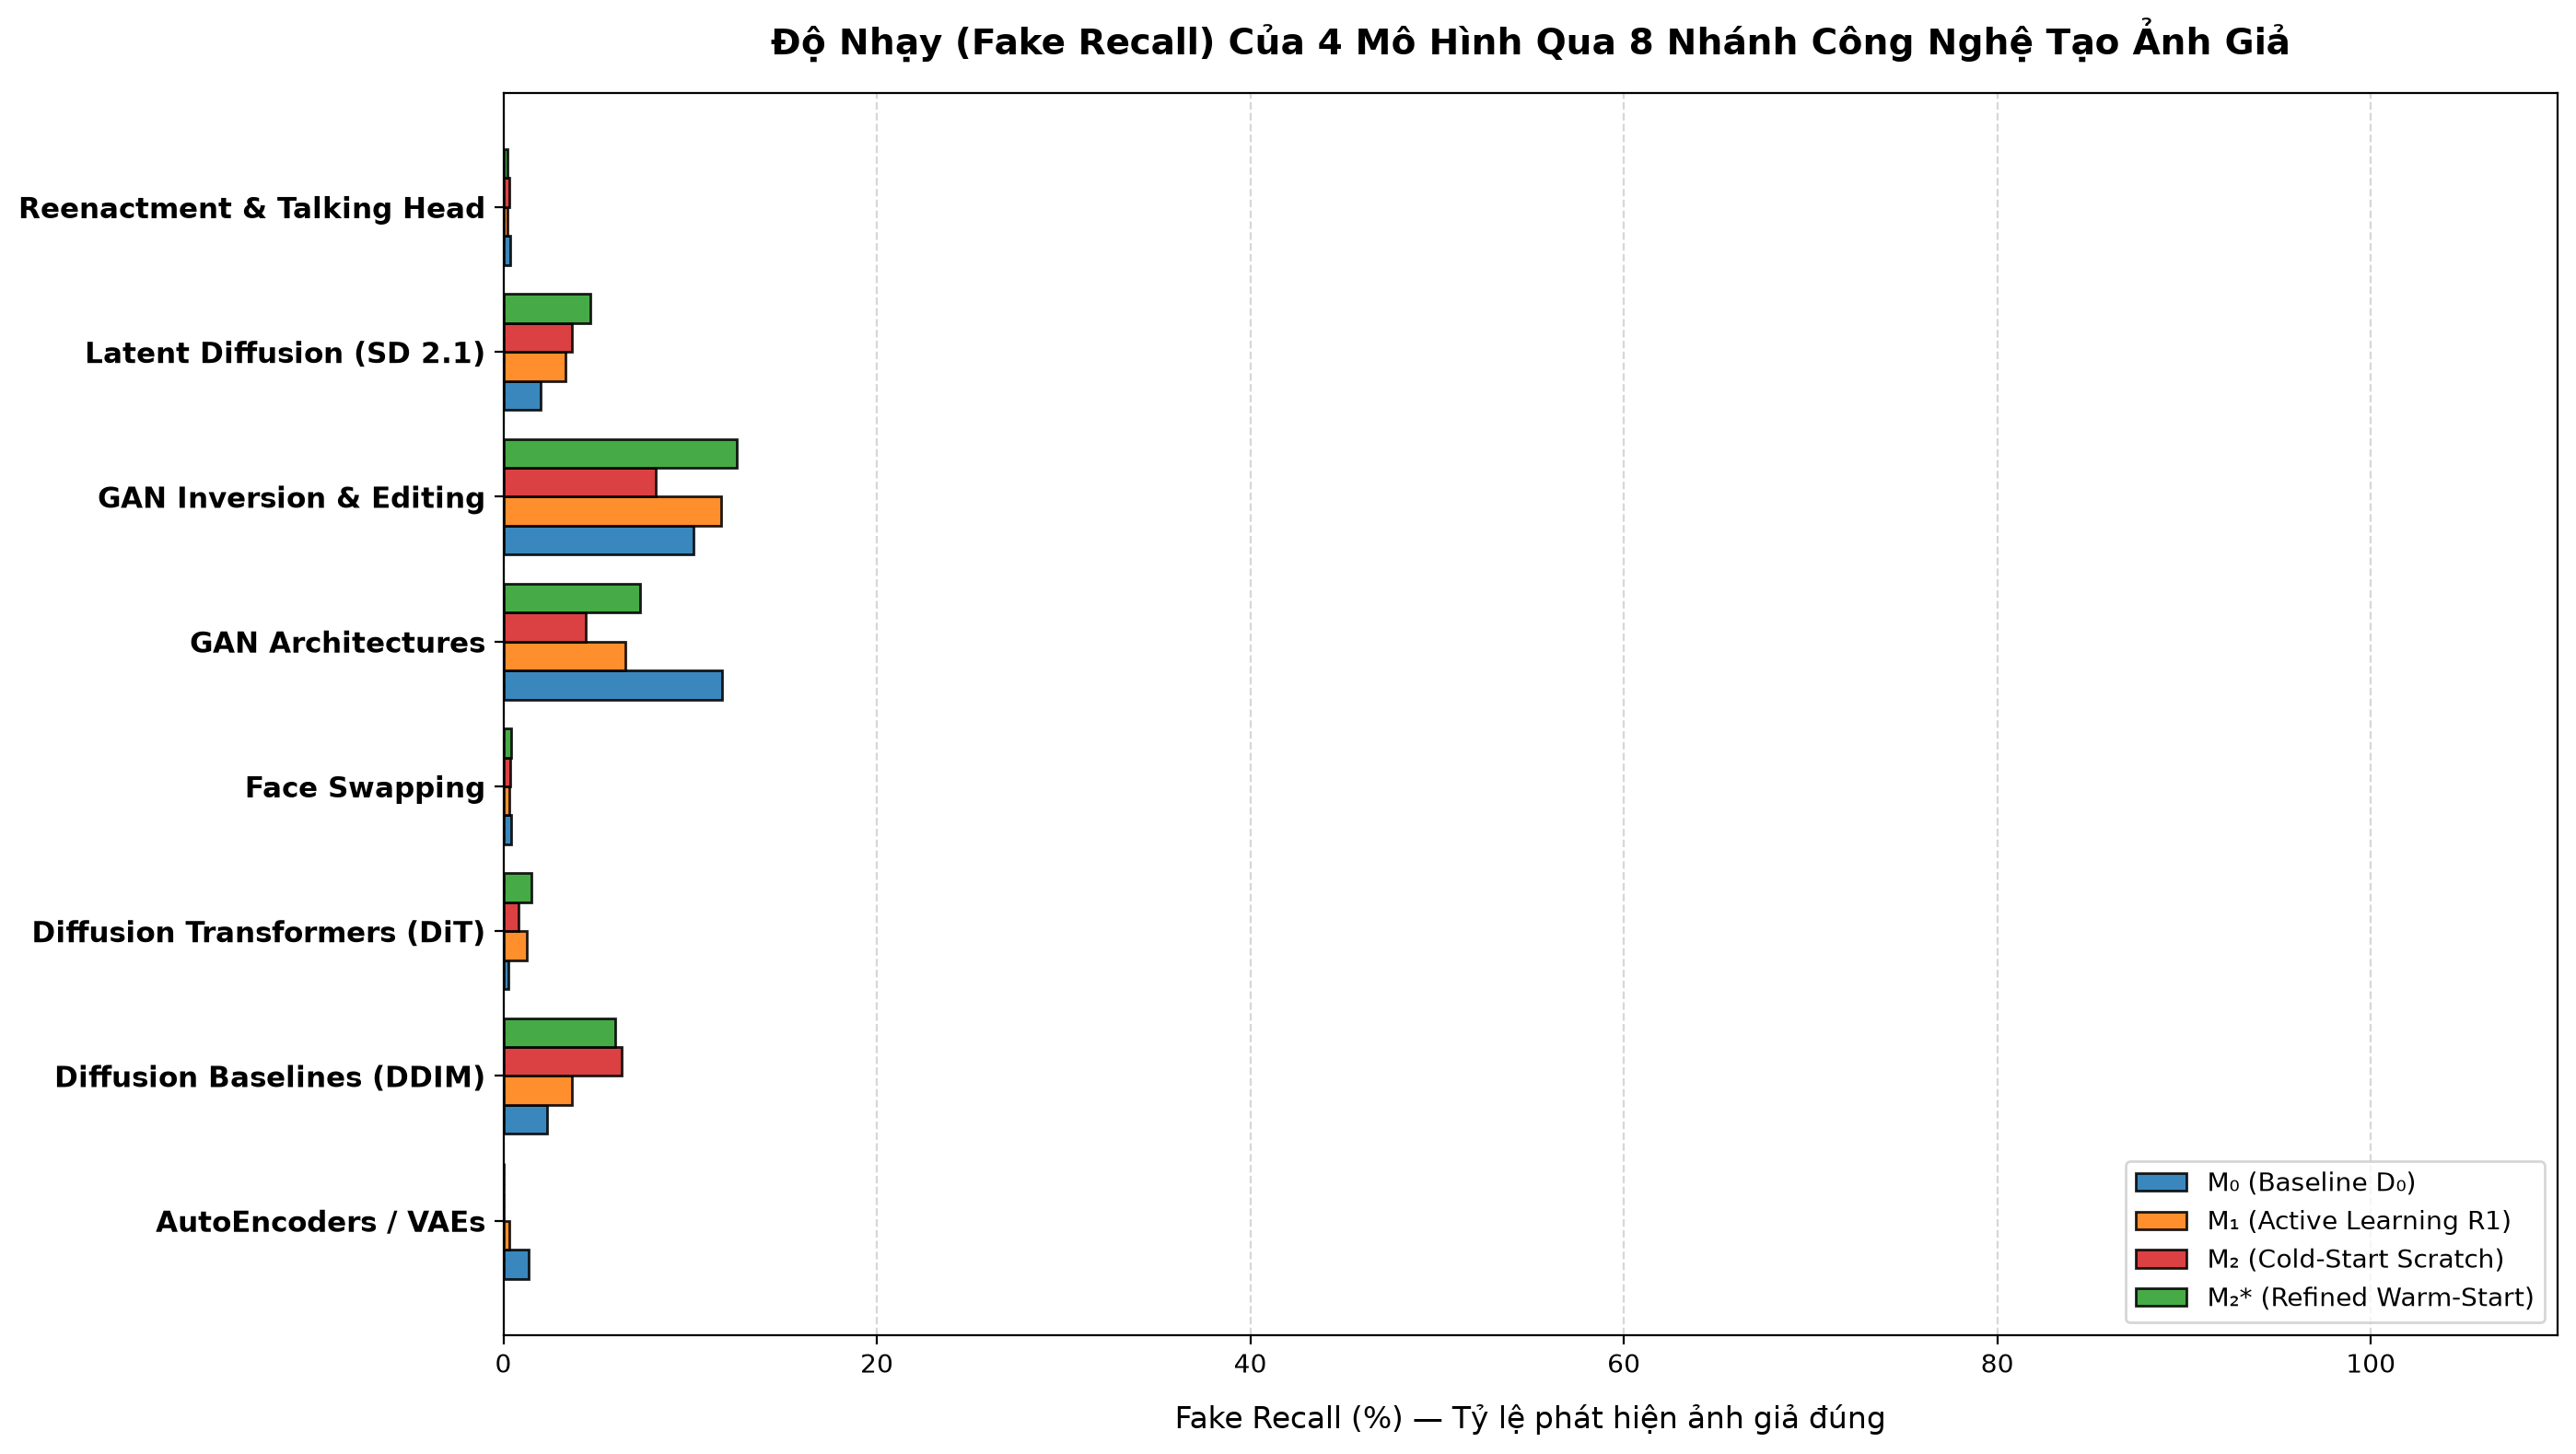

In [5]:
# --- [5. TRỰC QUAN HÓA HIỆU NĂNG THEO HỌ CÔNG NGHỆ] ---
display(IPImage(filename="experiments/benchmarks/figures/benchmark_4models_family_recall.png"))


### 4. Động Thái Đường Cong ROC và Precision-Recall Trên 20.400 Ảnh Mẫu

Đồ thị biểu diễn phân bố xác suất dự đoán và độ phân tách nhị phân giữa ảnh thật và ảnh giả qua 4 mô hình:


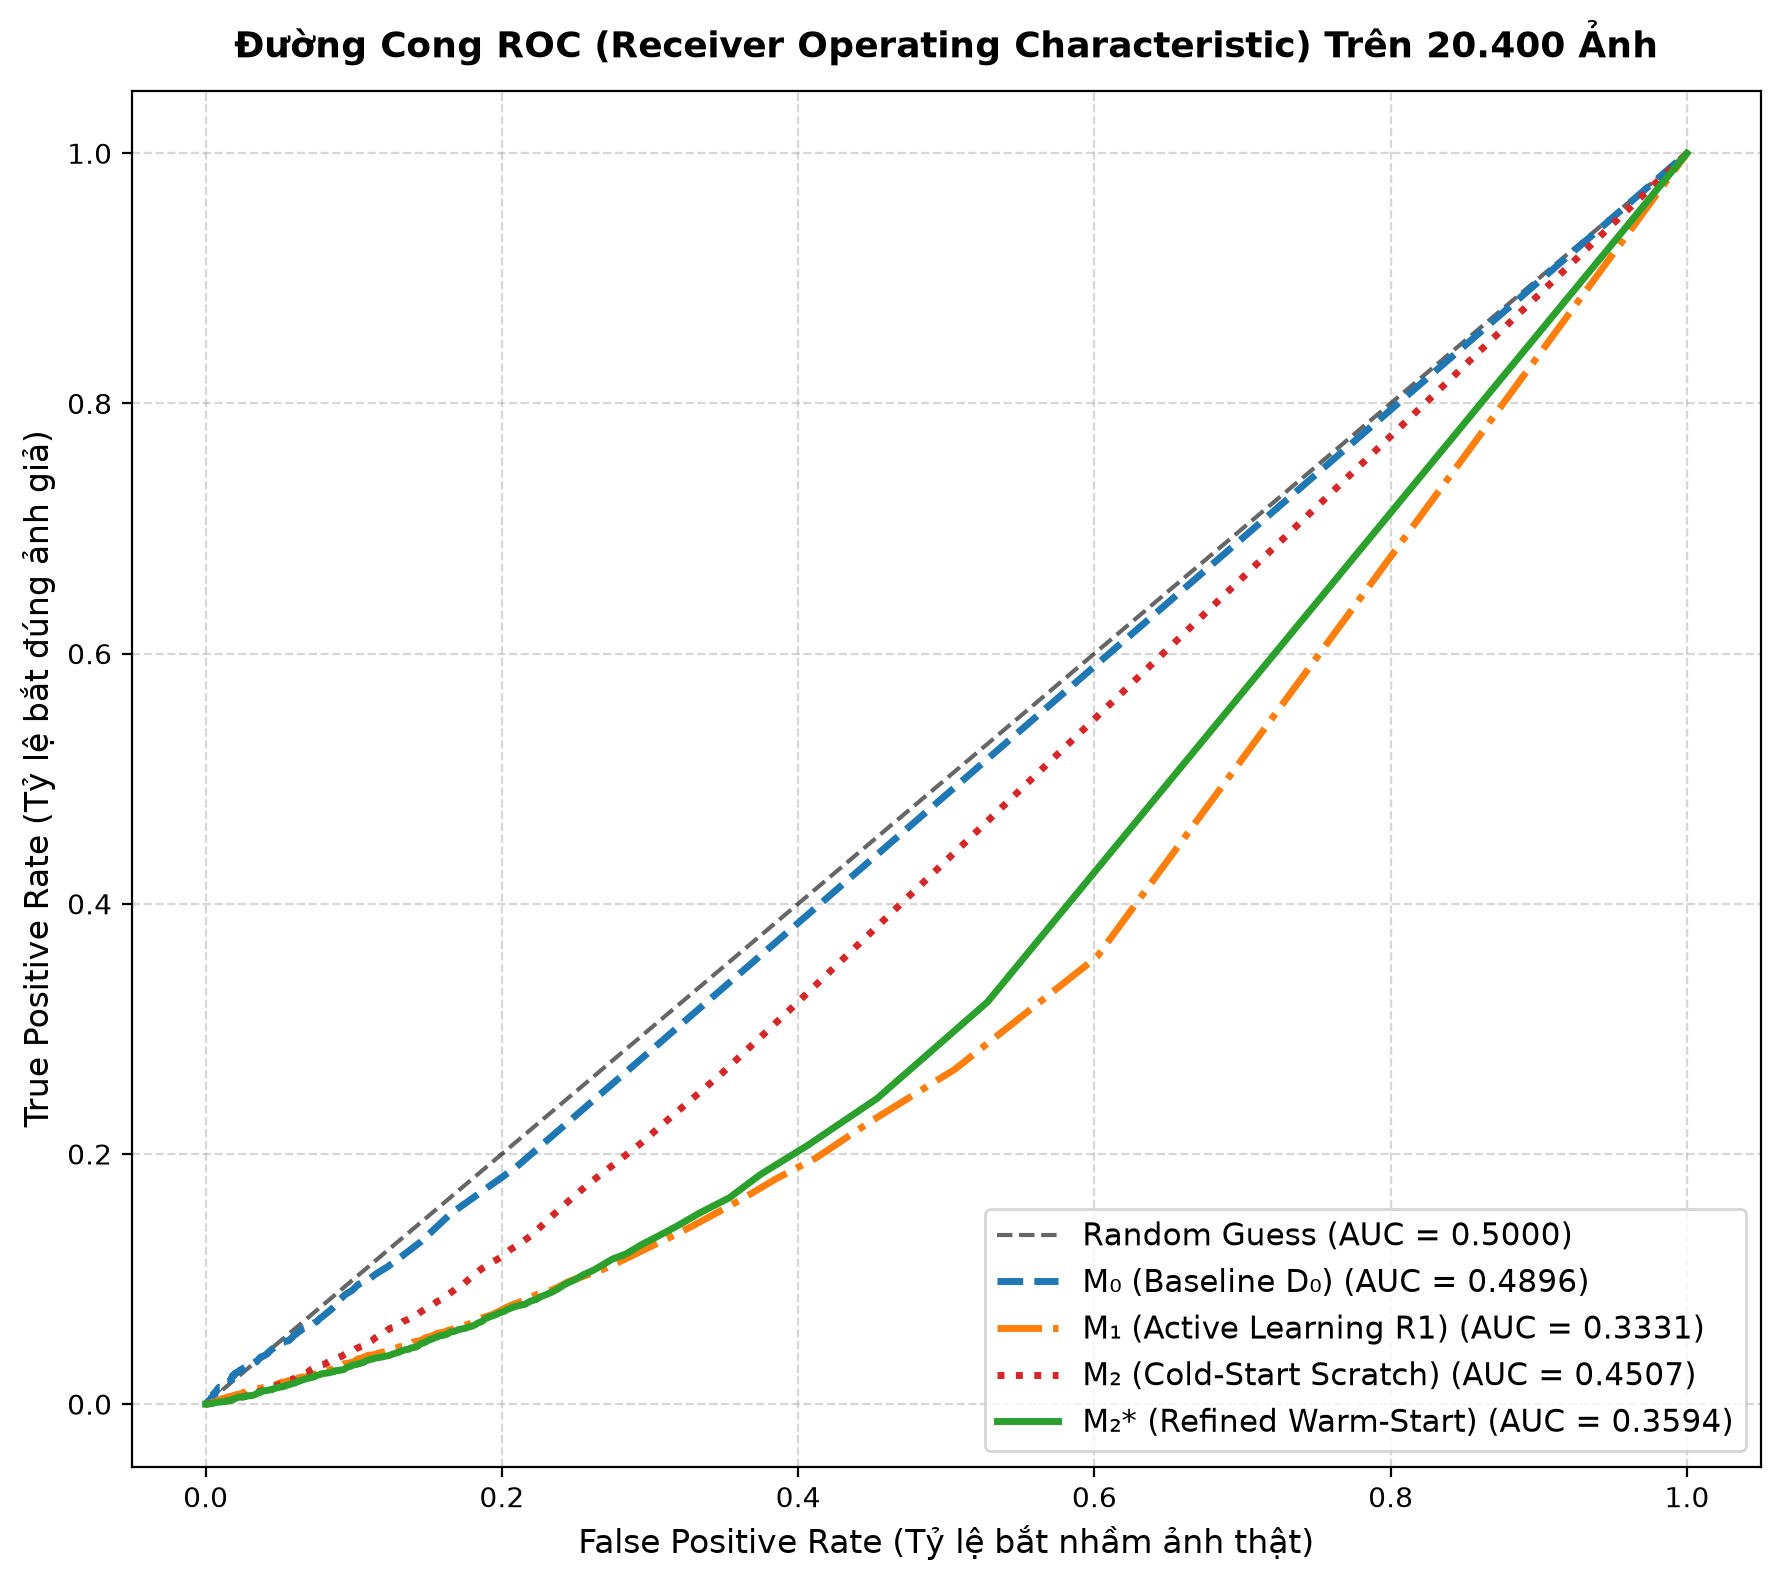

In [6]:
# --- [6. TRỰC QUAN HÓA ĐƯỜNG CONG ROC VÀ PRECISION-RECALL] ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
im_roc = Image.open("experiments/benchmarks/figures/benchmark_4models_roc_curves.png")
im_pr = Image.open("experiments/benchmarks/figures/benchmark_4models_precision_recall_curves.png")
ax1.imshow(im_roc)
ax1.axis("off")
ax1.set_title("Receiver Operating Characteristic (ROC)", fontsize=12, fontweight="bold")
ax2.imshow(im_pr)
ax2.axis("off")
ax2.set_title("Precision-Recall Curves", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


### 5. Bản Đồ Nhiệt Chi Tiết 34 Phương Pháp Tạo Ảnh Giả (34-Method Vulnerability Heatmap)

Ma trận nhiệt hiển thị chính xác Fake Recall (%) của từng phương pháp tạo ảnh giả độc lập (mỗi phương pháp chuẩn đúng 300 ảnh):
- **Các phương pháp bị phát hiện nhiều nhất**: `StyleGAN2` ($16.45\% - 27.98\%$), `e4e` ($26.88\%$), `styleclip` ($16.10\%$), `stargan` ($10.98\%$), `ddim` ($8.63\%$), `sd2.1` ($7.35\%$).
- **Các phương pháp là điểm mù (Blindspots)**: Các công cụ Talking Head và Face Swapping nhẹ nhàng như `wav2lip`, `fomm`, `fsgan`, `sadtalker`, `simswap`.


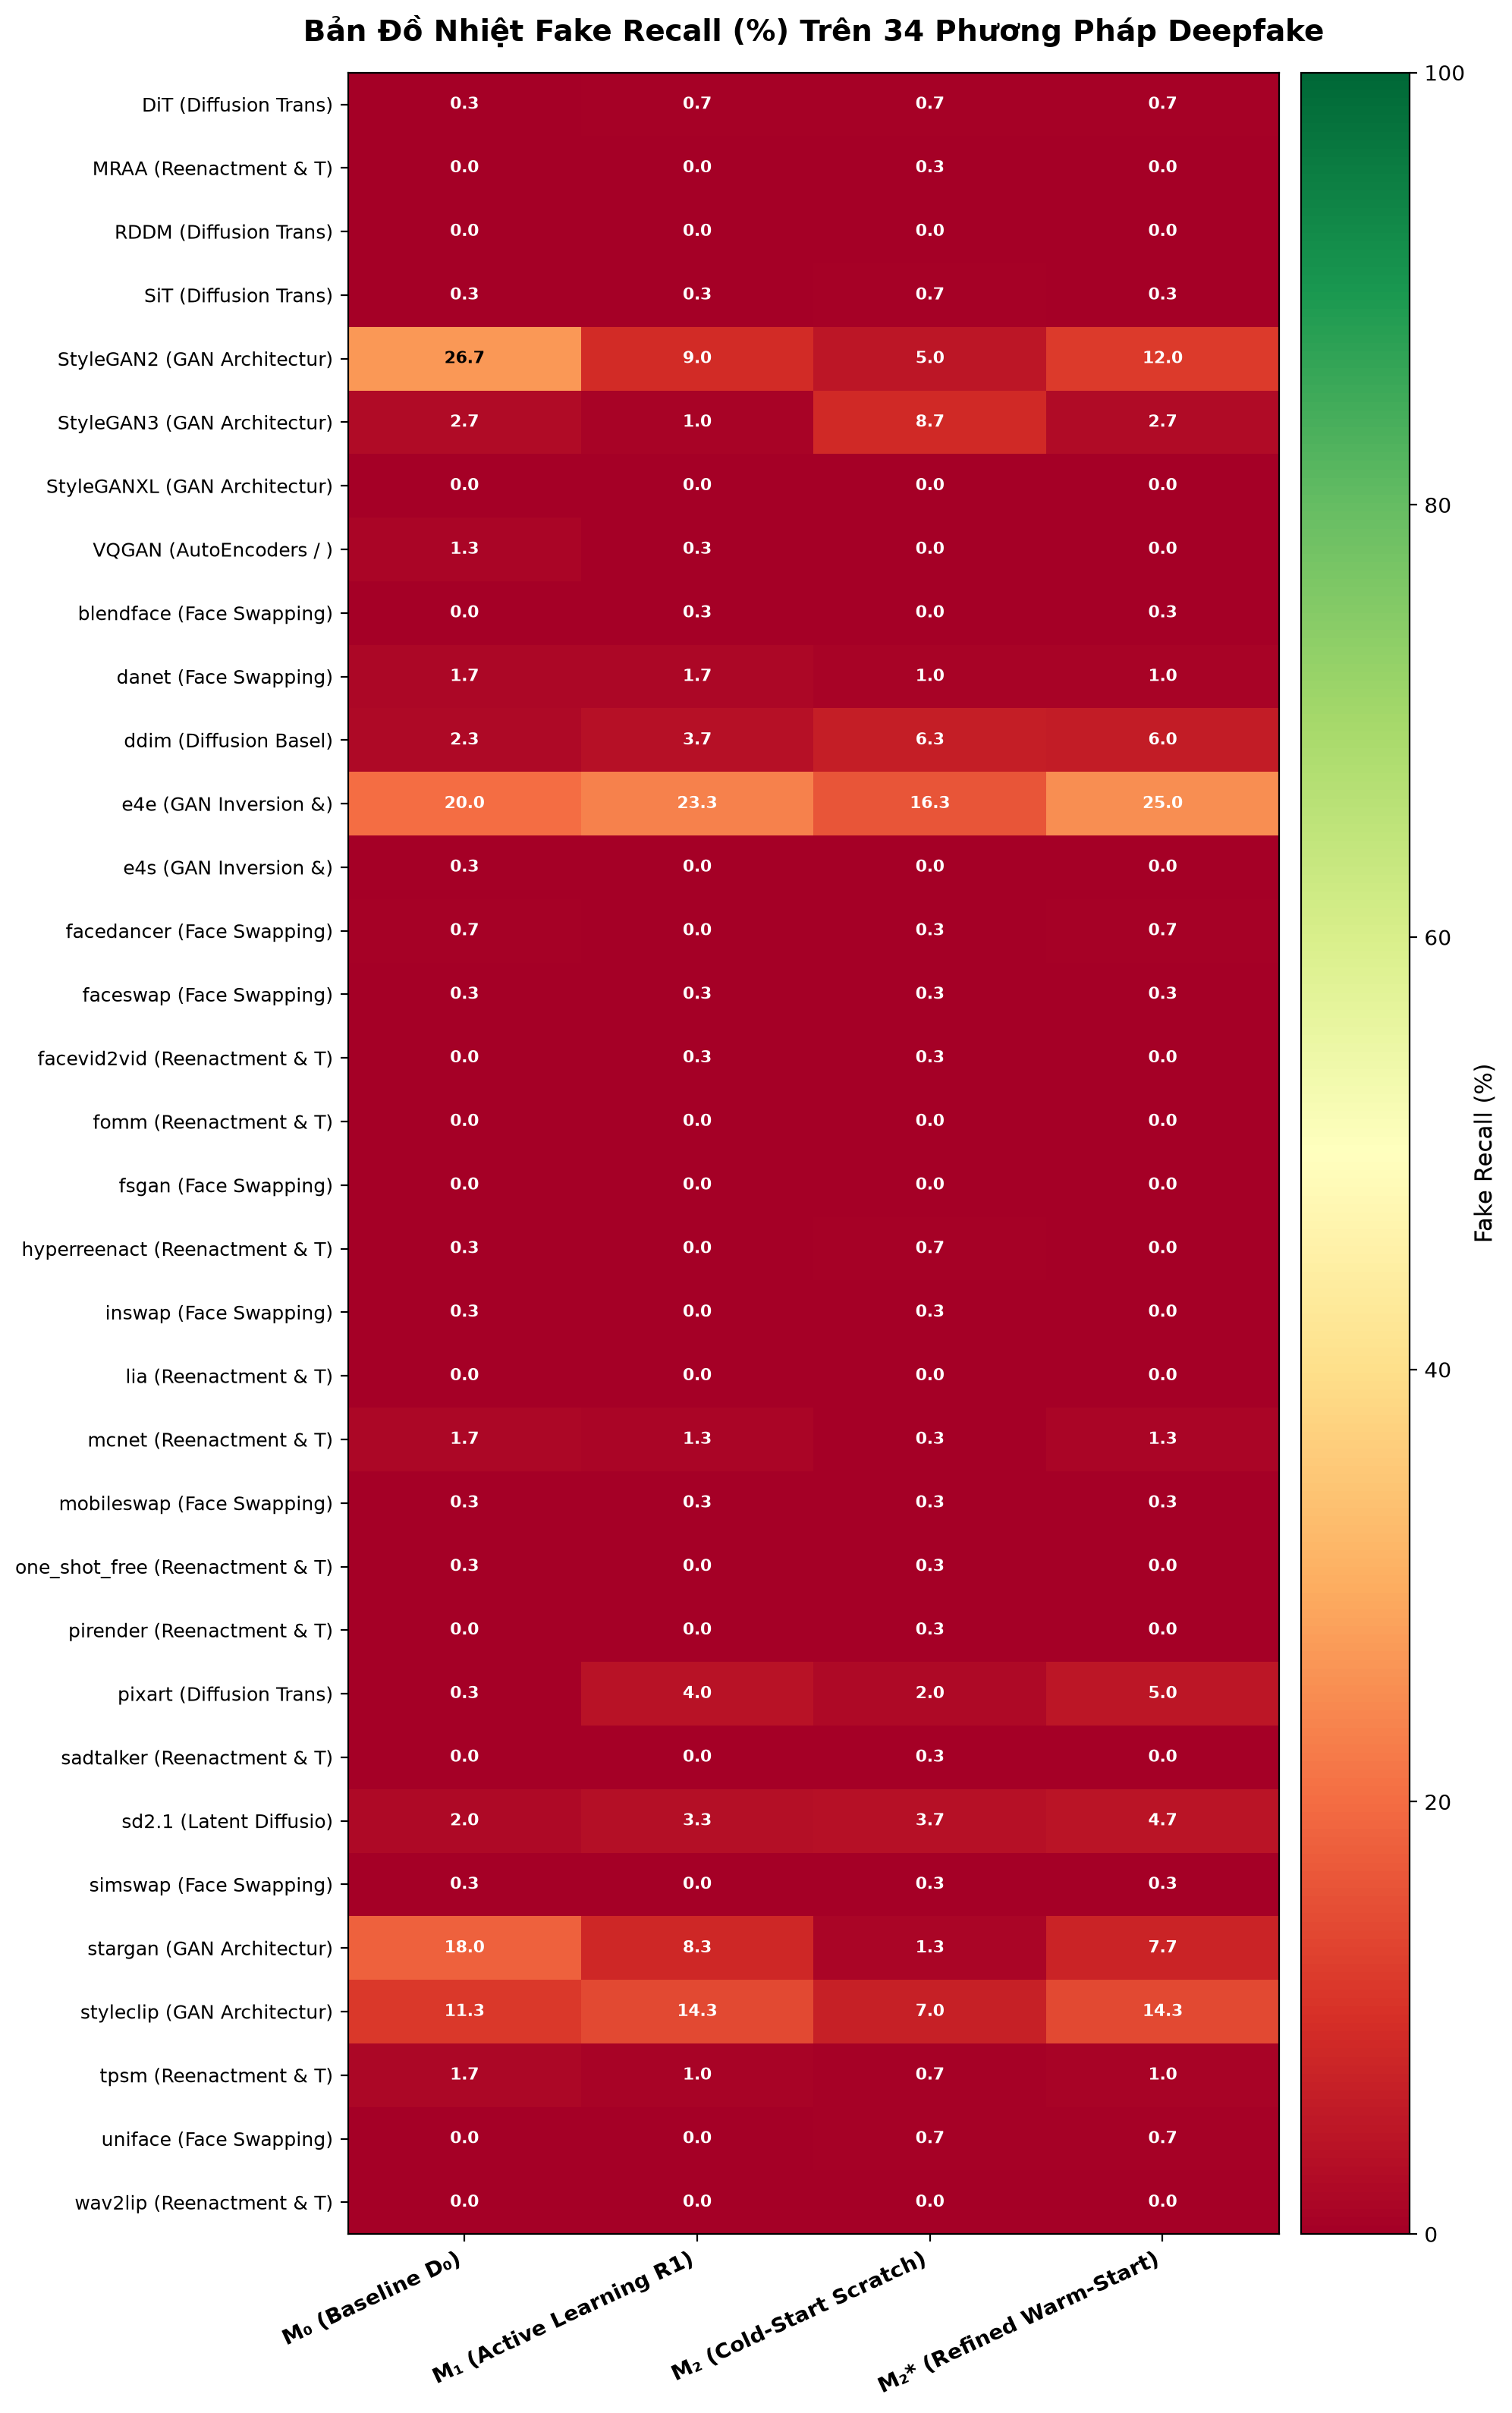

In [7]:
# --- [7. TRỰC QUAN HÓA BẢN ĐỒ NHIỆT 34 PHƯƠNG PHÁP] ---
display(IPImage(filename="experiments/benchmarks/figures/benchmark_4models_method_heatmap.png"))


### 6. Khảo Sát Dịch Chuyển Ngưỡng Quyết Định Phân Loại (Operating Threshold Sweep)

Vì mô hình được huấn luyện với hàm phạt False Alarm bảo thủ, phân bố xác suất $P(\text{Fake})$ có xu hướng tập trung ở dải giá trị nhỏ. Khi dịch chuyển ngưỡng $\tau$ từ $0.50$ xuống các mức nhạy cảm cao hơn, ta quan sát được sự đánh đổi giữa Fake Recall và Real Specificity:


In [8]:
# --- [8. KHẢO SÁT NGƯỠNG QUYẾT ĐỊNH TAU TRÊN M2* VÀ M0] ---
y = pred_data['y_true']
taus = [0.50, 0.20, 0.10, 0.05, 0.02, 0.01, 0.005]

print("=== BẢNG PHÂN TÍCH ĐÁNH ĐỔI NGƯỠNG TAU TRÊN MÔ HÌNH VÔ ĐỊCH M2* ===")
print(f"{'Ngưỡng Tau':10s} | {'Fake Recall (↑)':17s} | {'Bypass Rate (↓)':17s} | {'Real Specificity':17s} | {'Overall Acc'}")
print("-" * 80)
p_m2r = pred_data['probs_M2_refined_warmstart']
for t in taus:
    pred = (p_m2r >= t).astype(int)
    rec = float(np.mean(pred[y==1] == 1)) * 100
    byp = 100.0 - rec
    spec = float(np.mean(pred[y==0] == 0)) * 100
    acc = float(np.mean(pred == y)) * 100
    print(f"tau = {t:<6.3f} | {rec:>15.2f}% | {byp:>15.2f}% | {spec:>15.2f}% | {acc:>9.2f}%")


=== BẢNG PHÂN TÍCH ĐÁNH ĐỔI NGƯỠNG TAU TRÊN MÔ HÌNH VÔ ĐỊCH M2* ===
Ngưỡng Tau | Fake Recall (↑)   | Bypass Rate (↓)   | Real Specificity  | Overall Acc
--------------------------------------------------------------------------------
tau = 0.500  |            2.48% |           97.52% |           91.89% |     47.19%
tau = 0.200  |            5.18% |           94.82% |           84.83% |     45.00%
tau = 0.100  |            7.75% |           92.25% |           79.26% |     43.51%
tau = 0.050  |           10.95% |           89.05% |           73.47% |     42.21%
tau = 0.020  |           16.53% |           83.47% |           64.61% |     40.57%
tau = 0.010  |           22.29% |           77.71% |           57.54% |     39.92%
tau = 0.005  |           29.84% |           70.16% |           49.70% |     39.77%


### 7. Khảo Sát Tính Bền Vững Trên Ảnh Thật (Studio HQ vs Youtube C23 Compression)

Bộ Universal Benchmark bao gồm 2 nguồn ảnh thật đối chứng lớn:
1. **`ffhq_real` (8.352 ảnh)**: Ảnh chân dung chất lượng studio cao ($1024 \times 1024$).
2. **`ff++_real` (1.655 ảnh)**: Khung hình video nén H.264 (C23) cắt từ FaceForensics++ Youtube thực tế.

Dưới đây là tỷ lệ bắt nhầm ảnh thật (False Alarm / FPR) của từng mô hình qua các miền ảnh thật khác nhau:


In [9]:
# --- [9. PHÂN TÍCH TỶ LỆ FALSE ALARM TRÊN CÁC NGUỒN ẢNH THẬT] ---
sources = pred_data['sources']
real_mask = (y == 0)
models_keys = ['M0_baseline', 'M1_active_r1', 'M2_coldstart', 'M2_refined_warmstart']
models_names = ['M₀', 'M₁', 'M₂_cold', 'M₂*']

print(f"{'Nguồn Ảnh Thật':20s} | {'Số Lượng':8s} | {'M₀ FPR':8s} | {'M₁ FPR':8s} | {'M₂_cold FPR':11s} | {'M₂* FPR'}")
print("-" * 75)
for src in sorted(list(set(sources[real_mask]))):
    s_mask = (sources == src) & real_mask
    fprs = [float(np.mean(pred_data[f'probs_{k}'][s_mask] >= 0.50)) * 100 for k in models_keys]
    print(f"{src:20s} | {np.sum(s_mask):>8,d} | {fprs[0]:>7.2f}% | {fprs[1]:>7.2f}% | {fprs[2]:>10.2f}% | {fprs[3]:>7.2f}%")


Nguồn Ảnh Thật       | Số Lượng | M₀ FPR   | M₁ FPR   | M₂_cold FPR | M₂* FPR
---------------------------------------------------------------------------
ff++_real            |    1,655 |    0.18% |    1.39% |      0.79% |    1.45%
ffhq_real            |    8,352 |    2.81% |    7.89% |      6.32% |    9.59%
test_data_v3         |      193 |    1.55% |    1.04% |      0.00% |    1.04%


### 8. Công Cụ Khám Phá & So Sánh Dự Đoán Trực Quan Cả 4 Mô Hình (Interactive 4-Model Inspector)

Sử dụng hàm dưới đây để chọn bất kỳ phương pháp nào trong 34 phương pháp benchmark, hiển thị ảnh gốc và đối chứng kết quả dự đoán của cả 4 thế hệ mô hình side-by-side:


In [10]:
# --- [10. HÀM TƯƠNG TÁC: SO SÁNH 4 MÔ HÌNH TRÊN MẪU BẤT KỲ] ---
def inspect_4models_sample(method_name: str = "StyleGAN2", sample_idx: int = 0):
    benchmark_csv = Path("data/benchmarks/universal_deepfake_benchmark/splits/test_universal_deepfake_benchmark.csv")
    base_img_dir = Path("data/benchmarks/universal_deepfake_benchmark/test_images")
    
    with open(benchmark_csv, "r", encoding="utf-8") as f:
        all_rows = list(csv.DictReader(f))
    
    matches = [i for i, r in enumerate(all_rows) if r["method"] == method_name]
    if not matches:
        print(f"[!] Không tìm thấy phương pháp: {method_name}")
        return
    
    chosen_idx = matches[min(sample_idx, len(matches) - 1)]
    row = all_rows[chosen_idx]
    rel_path = row["path"].lstrip("/")
    full_p = base_img_dir / rel_path
    
    if not full_p.exists():
        print(f"[!] Ảnh không tồn tại trên đĩa: {full_p}")
        return
    
    im = Image.open(full_p).convert("RGB")
    
    # Lấy xác suất dự đoán của 4 mô hình tại vị trí chosen_idx
    p_m0 = pred_data["probs_M0_baseline"][chosen_idx]
    p_m1 = pred_data["probs_M1_active_r1"][chosen_idx]
    p_m2c = pred_data["probs_M2_coldstart"][chosen_idx]
    p_m2r = pred_data["probs_M2_refined_warmstart"][chosen_idx]
    
    probs_list = [p_m0, p_m1, p_m2c, p_m2r]
    labels = ["M₀ (Baseline)", "M₁ (Active R1)", "M₂ (Cold-Start)", "M₂* (Warm-Start)"]
    colors = ["#1f77b4", "#ff7f0e", "#d62728", "#2ca02c"]
    
    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(13, 5))
    ax_img.imshow(im)
    ax_img.set_title(f"Phương pháp: {method_name}\nNhãn thực tế: {'FAKE (1)' if row['label']=='1' else 'REAL (0)'}\nNguồn: {row['source']}", fontsize=11, fontweight="bold")
    ax_img.axis("off")
    
    bars = ax_bar.bar(labels, probs_list, color=colors, edgecolor="black", width=0.55)
    ax_bar.axhline(0.50, color="red", linestyle="--", linewidth=1.5, label="Ngưỡng quyết định (tau = 0.50)")
    ax_bar.set_ylim(0.0, 1.05)
    ax_bar.set_ylabel("Xác suất dự đoán là ảnh giả P(Fake)", fontsize=11)
    ax_bar.set_title("Đối Chứng Dự Đoán Của Cả 4 Thế Hệ Detector", fontsize=12, fontweight="bold")
    ax_bar.grid(axis="y", linestyle="--", alpha=0.5)
    ax_bar.legend(loc="upper right", frameon=True)
    
    for bar in bars:
        h = bar.get_height()
        verdict = "FAKE" if h >= 0.50 else "REAL"
        ax_bar.text(bar.get_x() + bar.get_width() / 2, h + 0.02, f"{h:.3f}\n[{verdict}]", ha="center", va="bottom", fontsize=9, fontweight="bold")
    
    plt.tight_layout()
    plt.show()

# Chạy thử nghiệm trên mẫu StyleGAN2
inspect_4models_sample("StyleGAN2", sample_idx=5)


Đang hiển thị đối chứng 4 mô hình trên mẫu StyleGAN2...
